In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
df = pd.read_csv('/content/breast_cancer_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe())

print("\nColumn Names:")
print(df.columns)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Column Names:
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'Target'],
      dtype='object')


In [4]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df['Target'].value_counts())

Missing Values:
0

Duplicate Records:
0

Target Distribution:
Target
1    357
0    212
Name: count, dtype: int64


In [5]:
df = df.drop_duplicates()

df = df.fillna(df.median(numeric_only=True))

print("Missing Values After Cleaning:", df.isnull().sum().sum())
print("Dataset Shape After Cleaning:", df.shape)

Missing Values After Cleaning: 0
Dataset Shape After Cleaning: (569, 31)


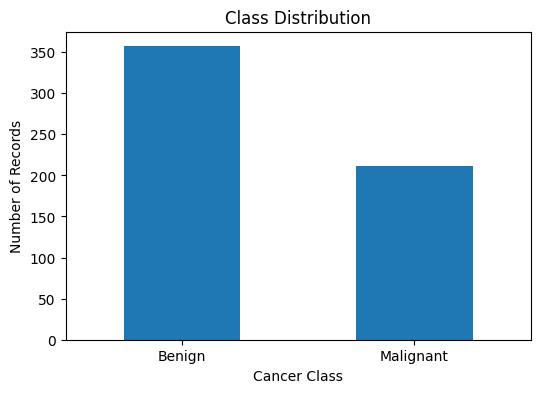

In [6]:
class_counts = df['Target'].map({
    0: 'Malignant',
    1: 'Benign'
}).value_counts()

plt.figure(figsize=(6, 4))
class_counts.plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Cancer Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [7]:
X = df.drop('Target', axis=1)

y = (df['Target'] == 0).astype(int)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Class Distribution:")
print(y.value_counts().rename(index={
    0: 'Benign',
    1: 'Malignant'
}))

Input Features Shape: (569, 30)
Target Shape: (569,)

Target Class Distribution:
Target
Benign       357
Malignant    212
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining Class Counts:")
print(y_train.value_counts())

print("\nTesting Class Counts:")
print(y_test.value_counts())

Training Records: 455
Testing Records: 114

Training Class Counts:
Target
0    285
1    170
Name: count, dtype: int64

Testing Class Counts:
Target
0    72
1    42
Name: count, dtype: int64


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


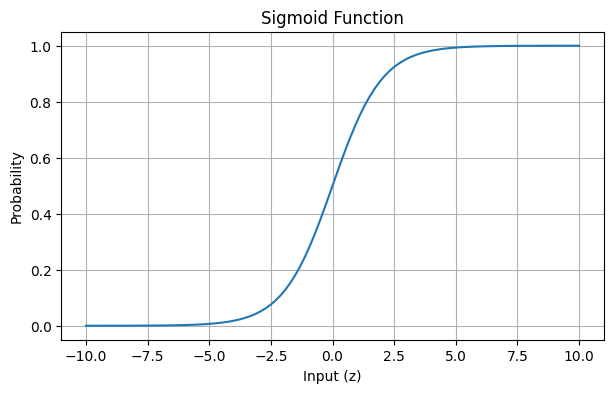

In [10]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid)
plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [11]:
model = LogisticRegression(max_iter=10000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [12]:
print("Model Intercept:")
print(model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

display(coefficients)

Model Intercept:
[-0.24300533]


,Feature,Coefficient
0,mean radius,0.361150
1,mean texture,0.482219
2,mean perimeter,0.353160
3,mean area,0.439950
4,mean smoothness,0.350622
5,mean compactness,-0.439546
6,mean concavity,0.782298
7,mean concave points,0.952813
8,mean symmetry,-0.163991
9,mean fractal dimension,-0.080865


In [13]:
y_probability = model.predict_proba(X_test_scaled)[:, 1]

y_pred = (y_probability >= 0.5).astype(int)

comparison = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Probability': y_probability,
    'Predicted Class': y_pred
})

display(comparison.head(10))

,Actual Class,Predicted Probability,Predicted Class
0,0,0.000365,0
1,1,1.000000,1
2,0,0.042568,0
3,1,0.576187,1
4,0,0.509155,1
5,0,0.000616,0
6,1,0.761534,1
7,0,0.001012,0
8,0,0.000569,0
9,0,0.010768,0


In [14]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:
    predictions = (y_probability >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted Positive': predictions.sum(),
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Predicted Positive,Accuracy,Precision,Recall,F1 Score
0,0.3,42,0.982456,0.97619,0.976190,0.97619
1,0.5,40,0.964912,0.97500,0.928571,0.95122
2,0.7,38,0.964912,1.00000,0.904762,0.95000


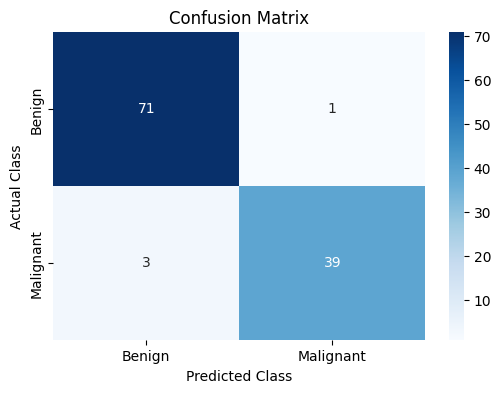

True Negative: 71
False Positive: 1
False Negative: 3
True Positive: 39


In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_probability)

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'Specificity',
        'F1 Score',
        'ROC-AUC'
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        auc
    ]
})

display(results)

,Metric,Value
0,Accuracy,0.964912
1,Precision,0.975000
2,Recall,0.928571
3,Specificity,0.986111
4,F1 Score,0.951220
5,ROC-AUC,0.996032


In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [18]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train_scaled, y_train)

baseline_pred = baseline.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Majority Class Baseline Accuracy:", baseline_accuracy)
print("Logistic Regression Accuracy:", accuracy)

Majority Class Baseline Accuracy: 0.631578947368421
Logistic Regression Accuracy: 0.9649122807017544


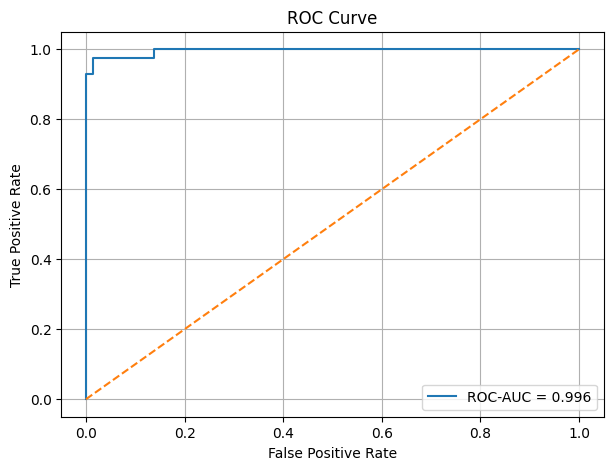

ROC-AUC Score: 0.996031746031746


In [19]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", auc)

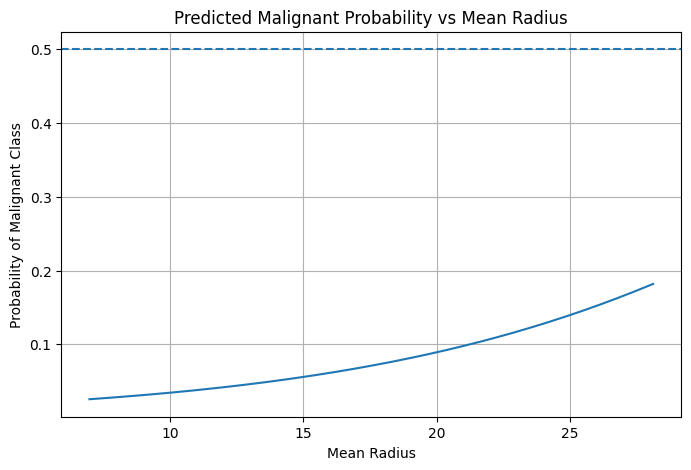

In [20]:
feature = 'mean radius'

feature_values = np.linspace(
    X_train[feature].min(),
    X_train[feature].max(),
    200
)

plot_data = pd.DataFrame(
    np.tile(X_train.median().values, (200, 1)),
    columns=X_train.columns
)

plot_data[feature] = feature_values

plot_scaled = scaler.transform(plot_data)

probabilities = model.predict_proba(plot_scaled)[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(feature_values, probabilities)
plt.axhline(0.5, linestyle='--')

plt.title("Predicted Malignant Probability vs Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Probability of Malignant Class")
plt.grid()
plt.show()

In [21]:
train_pred = model.predict(X_train_scaled)
test_pred = model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

performance = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'Accuracy': [train_accuracy, test_accuracy]
})

display(performance)

,Dataset,Accuracy
0,Training,0.986813
1,Testing,0.964912


In [22]:
new_data = pd.DataFrame(
    [X_train.median().values],
    columns=X_train.columns
)

new_data_scaled = scaler.transform(new_data)

new_probability = model.predict_proba(new_data_scaled)[0, 1]

new_prediction = int(new_probability >= 0.5)

print("Predicted Probability of Malignant Class:", new_probability)

if new_prediction == 1:
    print("Predicted Class: Malignant")
else:
    print("Predicted Class: Benign")

Predicted Probability of Malignant Class: 0.047635125105857275
Predicted Class: Benign


In [23]:
print("CONCLUSION")
print("Logistic Regression was successfully implemented using the Breast Cancer Wisconsin dataset.")
print("The dataset was divided into training and testing sets using an 80:20 stratified split.")
print("Feature scaling was performed using StandardScaler.")
print("The model was evaluated using confusion matrix, accuracy, precision, recall, specificity, F1-score and ROC-AUC.")
print("The model was also compared with a majority-class baseline.")
print("Different decision thresholds were compared to understand the trade-off between precision and recall.")
print("This model is for educational purposes only and must not be used for medical diagnosis.")

CONCLUSION
Logistic Regression was successfully implemented using the Breast Cancer Wisconsin dataset.
The dataset was divided into training and testing sets using an 80:20 stratified split.
Feature scaling was performed using StandardScaler.
The model was evaluated using confusion matrix, accuracy, precision, recall, specificity, F1-score and ROC-AUC.
The model was also compared with a majority-class baseline.
Different decision thresholds were compared to understand the trade-off between precision and recall.
This model is for educational purposes only and must not be used for medical diagnosis.
